In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
import seaborn as sns
plt.style.use('ggplot')

In [2]:
pd.set_option('display.max_columns', 200)

In [3]:
df = pd.read_csv('datasets/01_District_wise_crimes_committed_IPC_2001_2012.csv')

In [ ]:
# summary 
print("Dataset Info:")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nBasic Statistics:")
print(df.describe())

Dataset Info:
Shape: (9017, 33)
Columns: ['STATE/UT', 'DISTRICT', 'YEAR', 'MURDER', 'ATTEMPT TO MURDER', 'CULPABLE HOMICIDE NOT AMOUNTING TO MURDER', 'RAPE', 'CUSTODIAL RAPE', 'OTHER RAPE', 'KIDNAPPING & ABDUCTION', 'KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS', 'KIDNAPPING AND ABDUCTION OF OTHERS', 'DACOITY', 'PREPARATION AND ASSEMBLY FOR DACOITY', 'ROBBERY', 'BURGLARY', 'THEFT', 'AUTO THEFT', 'OTHER THEFT', 'RIOTS', 'CRIMINAL BREACH OF TRUST', 'CHEATING', 'COUNTERFIETING', 'ARSON', 'HURT/GREVIOUS HURT', 'DOWRY DEATHS', 'ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY', 'INSULT TO MODESTY OF WOMEN', 'CRUELTY BY HUSBAND OR HIS RELATIVES', 'IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES', 'CAUSING DEATH BY NEGLIGENCE', 'OTHER IPC CRIMES', 'TOTAL IPC CRIMES']

Data Types:
STATE/UT                                               object
DISTRICT                                               object
YEAR                                                    int64
MURDER                          

In [9]:
# Display first few rows to understand the data structure
print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,STATE/UT,DISTRICT,YEAR,MURDER,ATTEMPT TO MURDER,CULPABLE HOMICIDE NOT AMOUNTING TO MURDER,RAPE,CUSTODIAL RAPE,OTHER RAPE,KIDNAPPING & ABDUCTION,KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS,KIDNAPPING AND ABDUCTION OF OTHERS,DACOITY,PREPARATION AND ASSEMBLY FOR DACOITY,ROBBERY,BURGLARY,THEFT,AUTO THEFT,OTHER THEFT,RIOTS,CRIMINAL BREACH OF TRUST,CHEATING,COUNTERFIETING,ARSON,HURT/GREVIOUS HURT,DOWRY DEATHS,ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY,INSULT TO MODESTY OF WOMEN,CRUELTY BY HUSBAND OR HIS RELATIVES,IMPORTATION OF GIRLS FROM FOREIGN COUNTRIES,CAUSING DEATH BY NEGLIGENCE,OTHER IPC CRIMES,TOTAL IPC CRIMES
0,ANDHRA PRADESH,ADILABAD,2001,101,60,17,50,0,50,46,30,16,9,0,41,198,199,22,177,78,16,104,1,30,1131,16,149,34,175,0,181,1518,4154
1,ANDHRA PRADESH,ANANTAPUR,2001,151,125,1,23,0,23,53,30,23,8,0,16,191,366,57,309,168,11,65,8,69,1543,7,118,24,154,0,270,754,4125
2,ANDHRA PRADESH,CHITTOOR,2001,101,57,2,27,0,27,59,34,25,4,0,14,237,723,164,559,156,33,209,9,38,2088,14,112,83,186,0,404,1262,5818
3,ANDHRA PRADESH,CUDDAPAH,2001,80,53,1,20,0,20,25,20,5,1,0,4,98,173,36,137,164,12,37,2,23,795,17,126,38,57,0,233,1181,3140
4,ANDHRA PRADESH,EAST GODAVARI,2001,82,67,1,23,0,23,49,26,23,4,0,25,437,1021,150,871,70,50,220,3,41,1244,12,109,58,247,0,431,2313,6507


In [ ]:
# Explore unique values
print("Unique States/UTs:", df['STATE/UT'].nunique())
print("Unique Districts:", df['DISTRICT'].nunique())
print("Years covered:", sorted(df['YEAR'].unique()))
print("\nStates/UTs in the dataset:")
print(df['STATE/UT'].unique())

Unique States/UTs: 35
Unique Districts: 808
Years covered: [np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012)]

States/UTs in the dataset:
['ANDHRA PRADESH' 'ARUNACHAL PRADESH' 'ASSAM' 'BIHAR' 'CHHATTISGARH' 'GOA'
 'GUJARAT' 'HARYANA' 'HIMACHAL PRADESH' 'JAMMU & KASHMIR' 'JHARKHAND'
 'KARNATAKA' 'KERALA' 'MADHYA PRADESH' 'MAHARASHTRA' 'MANIPUR' 'MEGHALAYA'
 'MIZORAM' 'NAGALAND' 'ODISHA' 'PUNJAB' 'RAJASTHAN' 'SIKKIM' 'TAMIL NADU'
 'TRIPURA' 'UTTAR PRADESH' 'UTTARAKHAND' 'WEST BENGAL' 'A & N ISLANDS'
 'CHANDIGARH' 'D & N HAVELI' 'DAMAN & DIU' 'DELHI UT' 'LAKSHADWEEP'
 'PUDUCHERRY']


## 📊 Exploratory Data Analysis: Crime Trends in India (2001-2012)

Let's dive deep into the crime data and discover interesting patterns and trends across different states, districts, and crime types over the years.

/tmp/ipykernel_8596/1593258046.py:41: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


<Figure size 1500x800 with 0 Axes>

/home/cookie/aaa/ml/eda/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


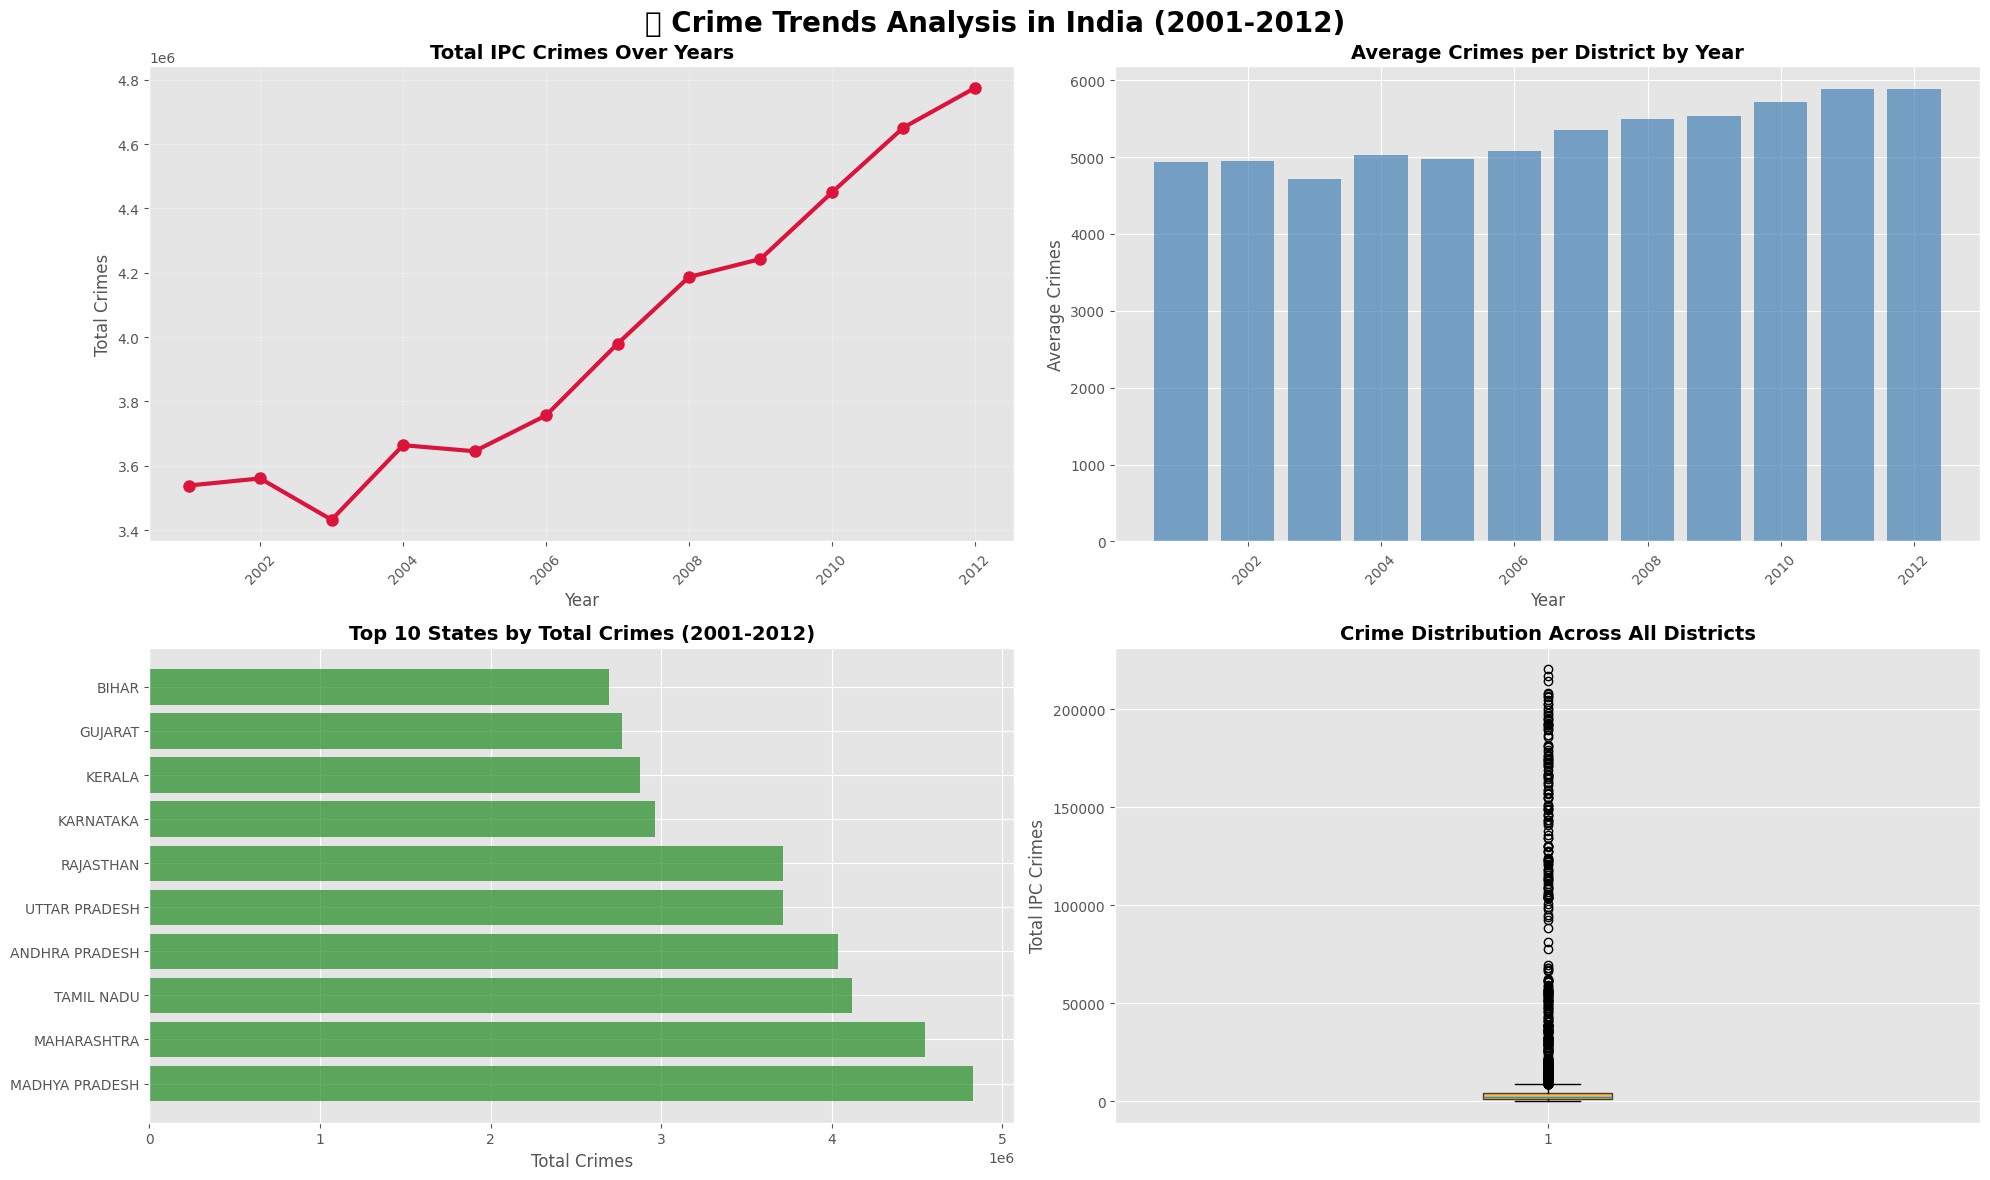

📊 Key Insights:
• Total crimes reported from 2001-2012: 47,881,308
• Highest crime year: 2012
• Lowest crime year: 2003
• Most crime-prone state: MADHYA PRADESH
• Average crimes per district per year: 5310.1


In [ ]:
# 1. Overall Crime Trends Over Years
plt.figure(figsize=(15, 8))

# Create subplot layout
fig, axes = plt.subplots(2, 2, figsize=(20, 12))
fig.suptitle('📈 Crime Trends Analysis in India (2001-2012)', fontsize=20, fontweight='bold')

# Total crimes by year
yearly_crimes = df.groupby('YEAR')['TOTAL IPC CRIMES'].sum().reset_index()
axes[0,0].plot(yearly_crimes['YEAR'], yearly_crimes['TOTAL IPC CRIMES'], 
               marker='o', linewidth=3, markersize=8, color='crimson')
axes[0,0].set_title('Total IPC Crimes Over Years', fontsize=14, fontweight='bold')
axes[0,0].set_xlabel('Year')
axes[0,0].set_ylabel('Total Crimes')
axes[0,0].grid(True, alpha=0.3)
axes[0,0].tick_params(axis='x', rotation=45)

# Average crimes per district by year
avg_crimes = df.groupby('YEAR')['TOTAL IPC CRIMES'].mean().reset_index()
axes[0,1].bar(avg_crimes['YEAR'], avg_crimes['TOTAL IPC CRIMES'], 
              color='steelblue', alpha=0.7)
axes[0,1].set_title('Average Crimes per District by Year', fontsize=14, fontweight='bold')
axes[0,1].set_xlabel('Year')
axes[0,1].set_ylabel('Average Crimes')
axes[0,1].tick_params(axis='x', rotation=45)

# Top 10 states by total crimes
state_crimes = df.groupby('STATE/UT')['TOTAL IPC CRIMES'].sum().sort_values(ascending=False).head(10)
axes[1,0].barh(range(len(state_crimes)), state_crimes.values, color='forestgreen', alpha=0.7)
axes[1,0].set_yticks(range(len(state_crimes)))
axes[1,0].set_yticklabels(state_crimes.index, fontsize=10)
axes[1,0].set_title('Top 10 States by Total Crimes (2001-2012)', fontsize=14, fontweight='bold')
axes[1,0].set_xlabel('Total Crimes')

# Crime distribution (box plot)
axes[1,1].boxplot(df['TOTAL IPC CRIMES'], patch_artist=True, 
                  boxprops=dict(facecolor='orange', alpha=0.7))
axes[1,1].set_title('Crime Distribution Across All Districts', fontsize=14, fontweight='bold')
axes[1,1].set_ylabel('Total IPC Crimes')

plt.tight_layout()
plt.show()

print(f"📊 Key Insights:")
print(f"• Total crimes reported from 2001-2012: {df['TOTAL IPC CRIMES'].sum():,}")
print(f"• Highest crime year: {yearly_crimes.loc[yearly_crimes['TOTAL IPC CRIMES'].idxmax(), 'YEAR']}")
print(f"• Lowest crime year: {yearly_crimes.loc[yearly_crimes['TOTAL IPC CRIMES'].idxmin(), 'YEAR']}")
print(f"• Most crime-prone state: {state_crimes.index[0]}")
print(f"• Average crimes per district per year: {df['TOTAL IPC CRIMES'].mean():.1f}")

/tmp/ipykernel_8596/1404625855.py:66: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


<Figure size 1800x1000 with 0 Axes>

/home/cookie/aaa/ml/eda/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


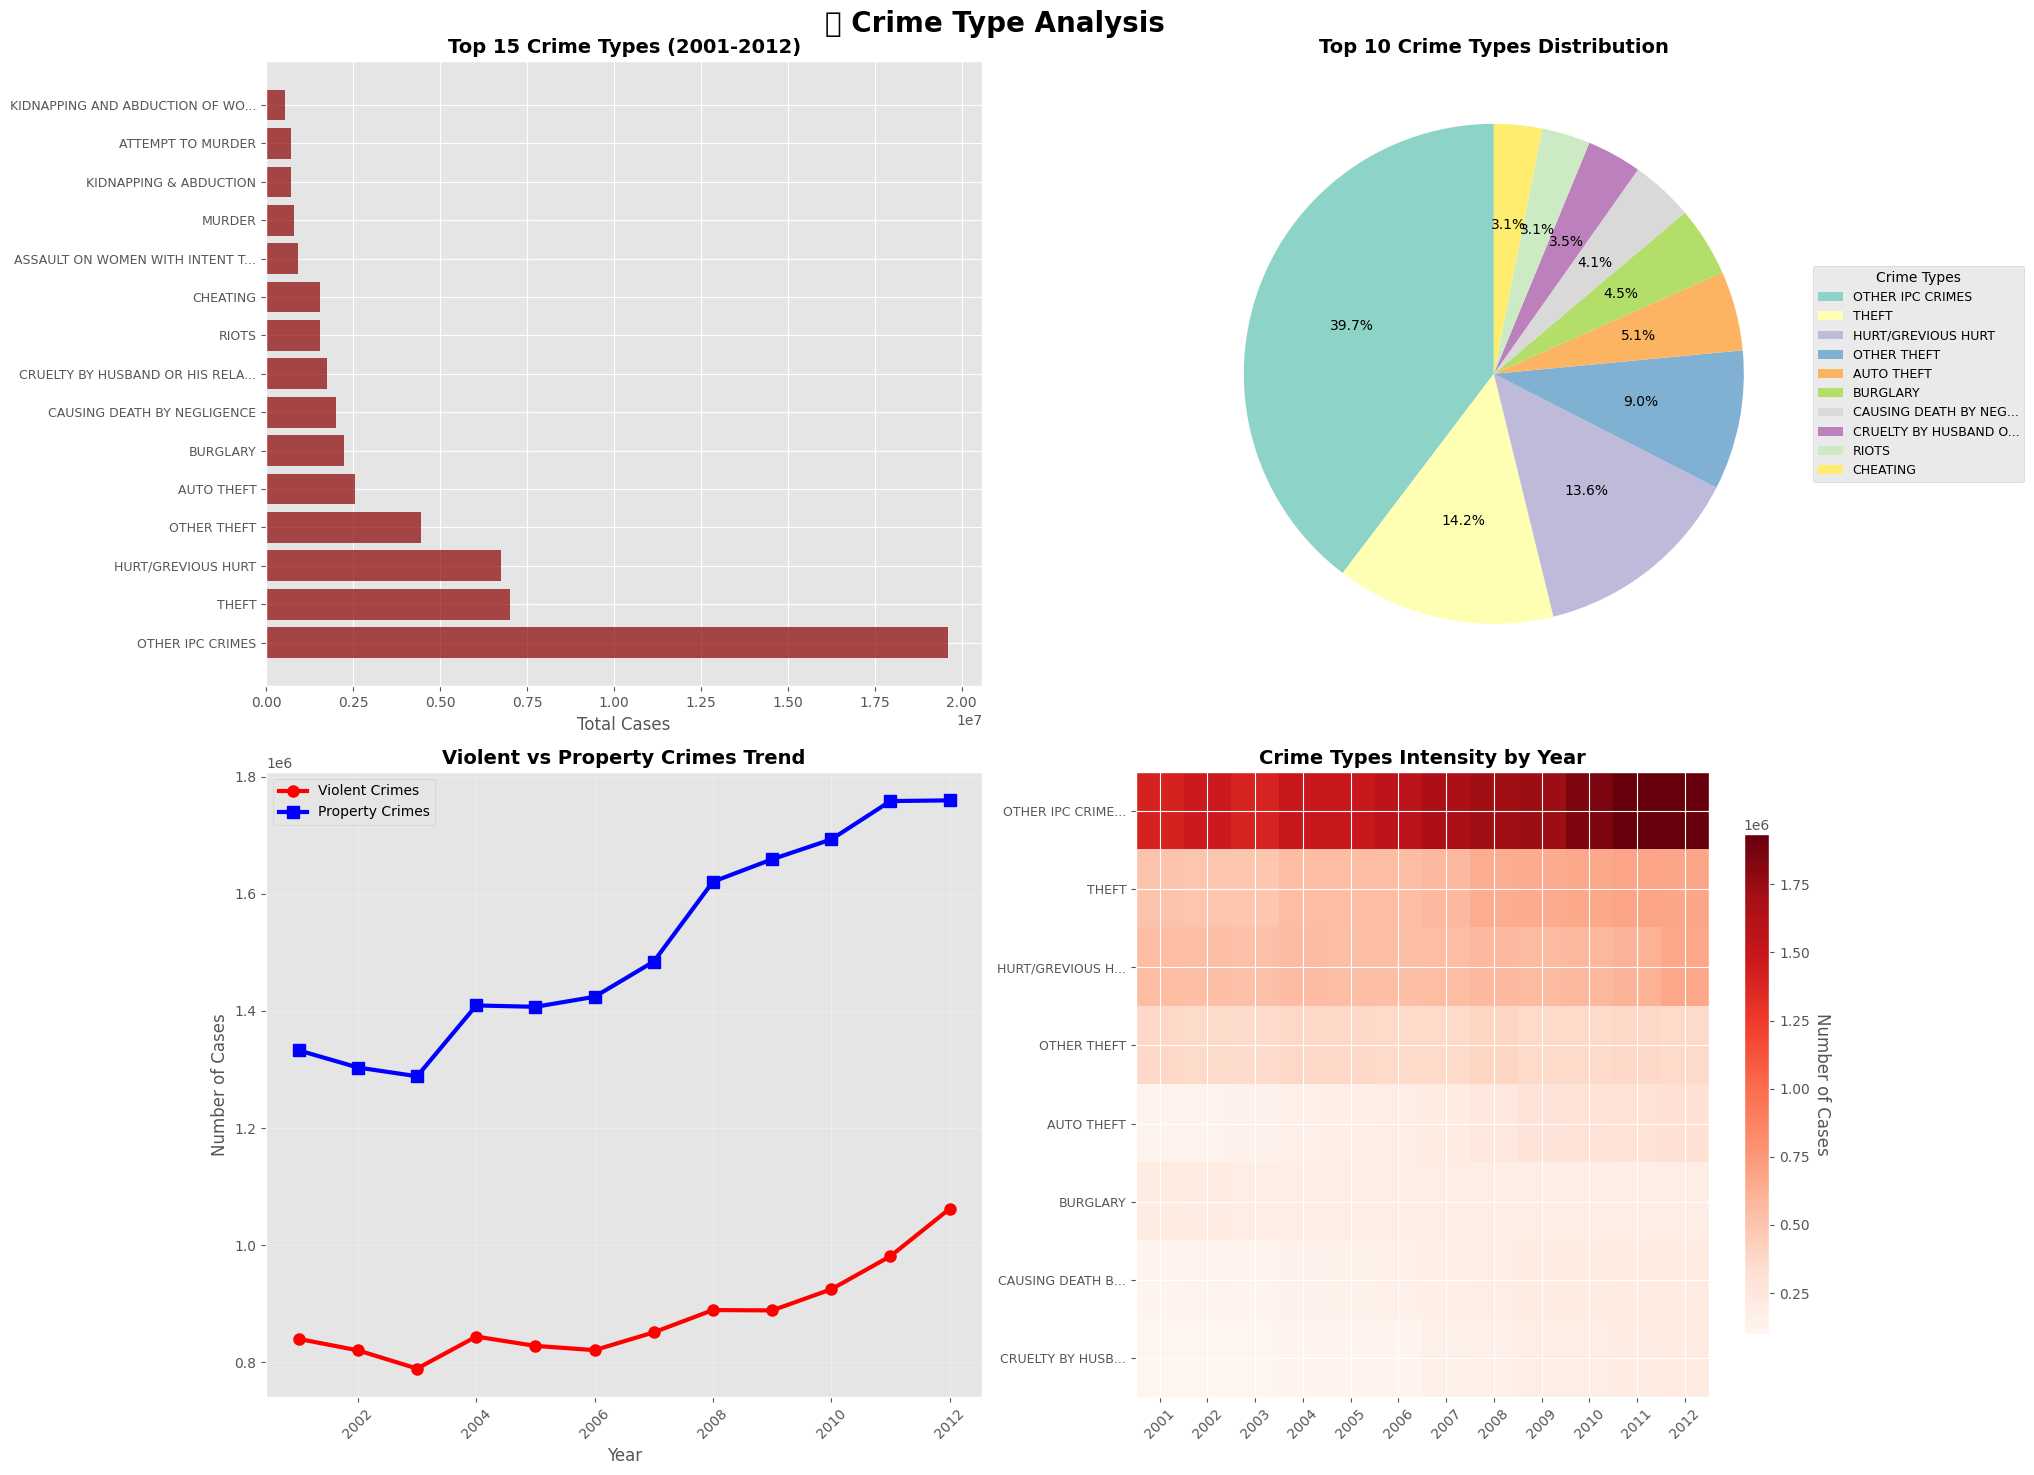

🎯 Crime Type Insights:
• Most common crime: OTHER IPC CRIMES (19,605,658 cases)
• Second most common: THEFT (7,001,060 cases)
• Third most common: HURT/GREVIOUS HURT (6,743,752 cases)
• Total violent crimes: 10,538,406
• Total property crimes: 18,140,034


In [12]:
# 2. Crime Type Analysis - Most Common Crimes
plt.figure(figsize=(18, 10))

# Get all crime columns (excluding metadata columns)
crime_columns = [col for col in df.columns if col not in ['STATE/UT', 'DISTRICT', 'YEAR', 'TOTAL IPC CRIMES']]

# Calculate total for each crime type
crime_totals = df[crime_columns].sum().sort_values(ascending=False)

# Create subplots for crime analysis
fig, axes = plt.subplots(2, 2, figsize=(20, 15))
fig.suptitle('🔍 Crime Type Analysis', fontsize=20, fontweight='bold')

# Top 15 crime types
top_crimes = crime_totals.head(15)
axes[0,0].barh(range(len(top_crimes)), top_crimes.values, color='darkred', alpha=0.7)
axes[0,0].set_yticks(range(len(top_crimes)))
axes[0,0].set_yticklabels([crime[:30] + '...' if len(crime) > 30 else crime for crime in top_crimes.index], fontsize=9)
axes[0,0].set_title('Top 15 Crime Types (2001-2012)', fontsize=14, fontweight='bold')
axes[0,0].set_xlabel('Total Cases')

# Crime type proportions (pie chart for top 10)
top_10_crimes = crime_totals.head(10)
colors = plt.cm.Set3(np.linspace(0, 1, len(top_10_crimes)))
wedges, texts, autotexts = axes[0,1].pie(top_10_crimes.values, labels=None, autopct='%1.1f%%', 
                                        colors=colors, startangle=90)
axes[0,1].set_title('Top 10 Crime Types Distribution', fontsize=14, fontweight='bold')

# Legend for pie chart
axes[0,1].legend(wedges, [crime[:20] + '...' if len(crime) > 20 else crime for crime in top_10_crimes.index],
                title="Crime Types", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1), fontsize=9)

# Violent vs Property crimes trend
violent_crimes = ['MURDER', 'ATTEMPT TO MURDER', 'RAPE', 'OTHER RAPE', 'CUSTODIAL RAPE', 
                 'KIDNAPPING & ABDUCTION', 'DACOITY', 'ROBBERY', 'HURT/GREVIOUS HURT']
property_crimes = ['THEFT', 'AUTO THEFT', 'OTHER THEFT', 'BURGLARY', 'CHEATING', 'CRIMINAL BREACH OF TRUST']

# Calculate yearly trends for violent vs property crimes
yearly_violent = df.groupby('YEAR')[violent_crimes].sum().sum(axis=1)
yearly_property = df.groupby('YEAR')[property_crimes].sum().sum(axis=1)

axes[1,0].plot(yearly_violent.index, yearly_violent.values, marker='o', linewidth=3, 
               label='Violent Crimes', color='red', markersize=8)
axes[1,0].plot(yearly_property.index, yearly_property.values, marker='s', linewidth=3, 
               label='Property Crimes', color='blue', markersize=8)
axes[1,0].set_title('Violent vs Property Crimes Trend', fontsize=14, fontweight='bold')
axes[1,0].set_xlabel('Year')
axes[1,0].set_ylabel('Number of Cases')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)
axes[1,0].tick_params(axis='x', rotation=45)

# Heatmap of crime types by year
crime_year_matrix = df.groupby('YEAR')[top_crimes.head(8).index].sum().T
im = axes[1,1].imshow(crime_year_matrix.values, cmap='Reds', aspect='auto')
axes[1,1].set_xticks(range(len(crime_year_matrix.columns)))
axes[1,1].set_xticklabels(crime_year_matrix.columns, rotation=45)
axes[1,1].set_yticks(range(len(crime_year_matrix.index)))
axes[1,1].set_yticklabels([crime[:15] + '...' if len(crime) > 15 else crime for crime in crime_year_matrix.index], fontsize=9)
axes[1,1].set_title('Crime Types Intensity by Year', fontsize=14, fontweight='bold')

# Add colorbar
cbar = plt.colorbar(im, ax=axes[1,1], shrink=0.8)
cbar.set_label('Number of Cases', rotation=270, labelpad=15)

plt.tight_layout()
plt.show()

print(f"🎯 Crime Type Insights:")
print(f"• Most common crime: {top_crimes.index[0]} ({top_crimes.iloc[0]:,} cases)")
print(f"• Second most common: {top_crimes.index[1]} ({top_crimes.iloc[1]:,} cases)")
print(f"• Third most common: {top_crimes.index[2]} ({top_crimes.iloc[2]:,} cases)")
print(f"• Total violent crimes: {yearly_violent.sum():,}")
print(f"• Total property crimes: {yearly_property.sum():,}")

/tmp/ipykernel_8596/4153536444.py:68: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/cookie/aaa/ml/eda/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/cookie/aaa/ml/eda/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


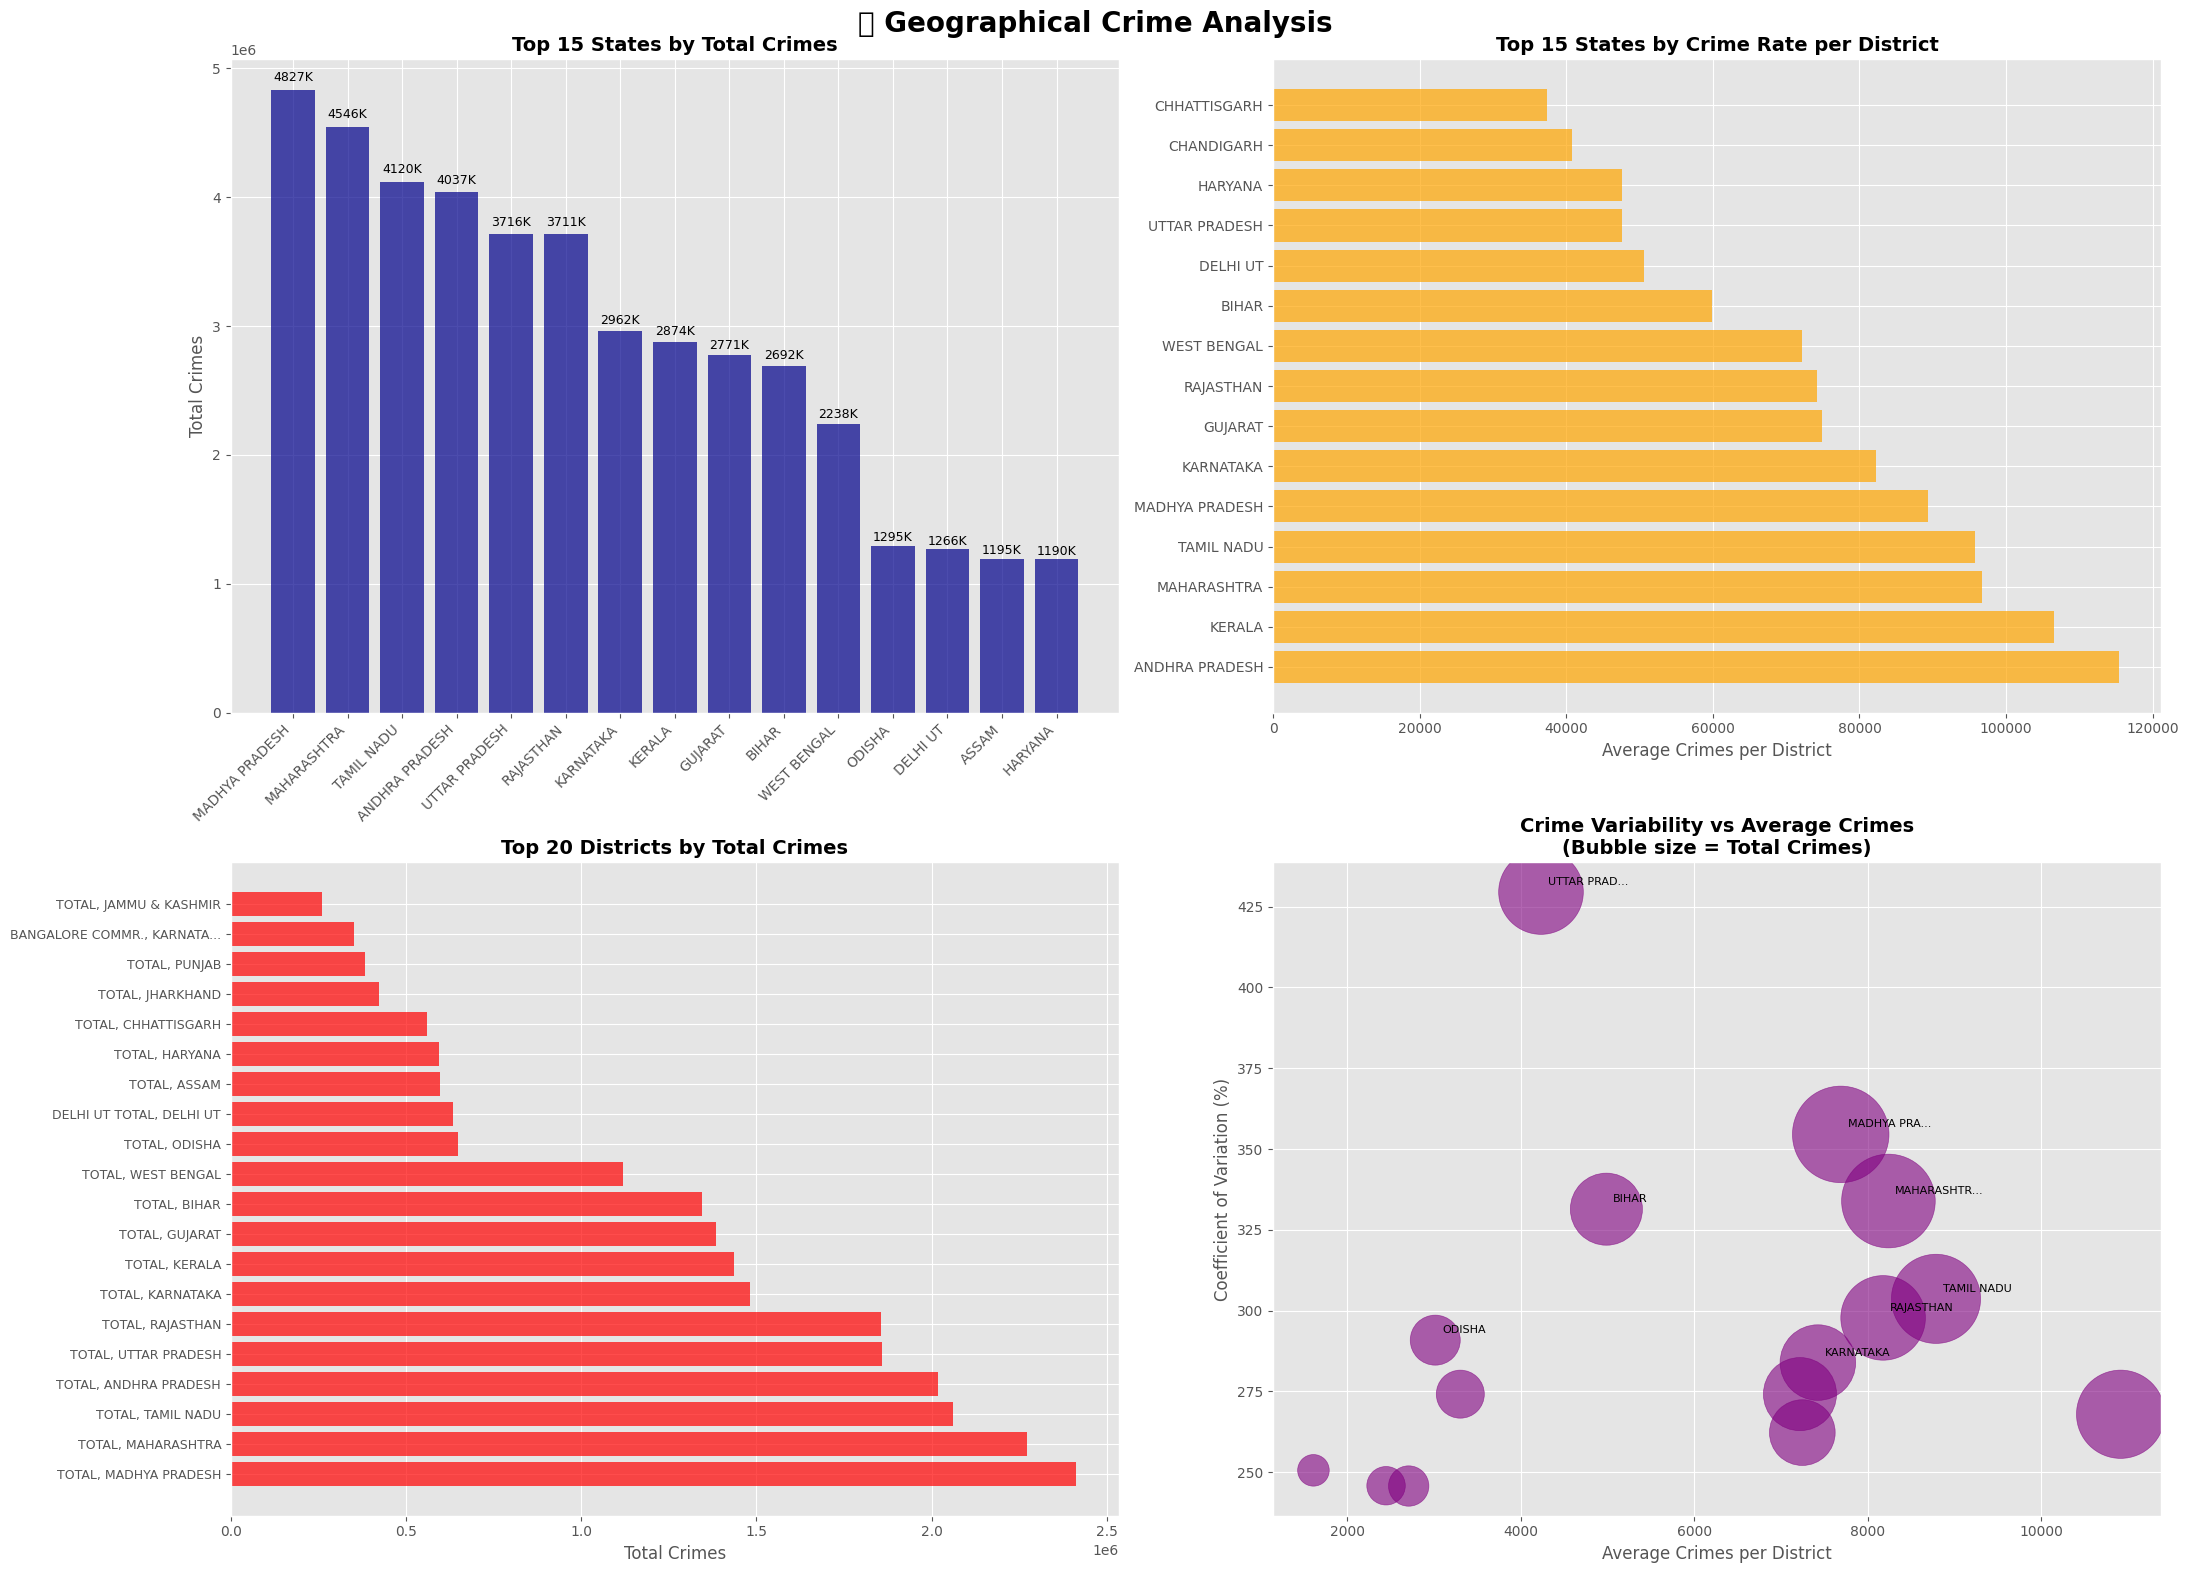

🌍 Geographical Insights:
• Highest crime state: MADHYA PRADESH (4,827,540.0 total crimes)
• Highest crime rate per district: ANDHRA PRADESH (115370.3 crimes/district)
• Most crime-prone district: TOTAL, MADHYA PRADESH (2,413,770 crimes)
• States analyzed: 35
• Districts analyzed: 808


In [13]:
# 3. Geographical Analysis - State and District Level Insights
fig, axes = plt.subplots(2, 2, figsize=(22, 16))
fig.suptitle('🗺️ Geographical Crime Analysis', fontsize=20, fontweight='bold')

# State-wise crime rate analysis
state_analysis = df.groupby('STATE/UT').agg({
    'TOTAL IPC CRIMES': ['sum', 'mean', 'std'],
    'DISTRICT': 'nunique'
}).round(2)

state_analysis.columns = ['Total_Crimes', 'Avg_Crimes', 'Std_Crimes', 'Num_Districts']
state_analysis['Crime_Rate_Per_District'] = state_analysis['Total_Crimes'] / state_analysis['Num_Districts']
state_analysis = state_analysis.sort_values('Total_Crimes', ascending=False)

# Top states by total crimes
top_15_states = state_analysis.head(15)
bars = axes[0,0].bar(range(len(top_15_states)), top_15_states['Total_Crimes'], 
                     color='darkblue', alpha=0.7)
axes[0,0].set_xticks(range(len(top_15_states)))
axes[0,0].set_xticklabels(top_15_states.index, rotation=45, ha='right', fontsize=10)
axes[0,0].set_title('Top 15 States by Total Crimes', fontsize=14, fontweight='bold')
axes[0,0].set_ylabel('Total Crimes')

# Add value labels on bars
for i, bar in enumerate(bars):
    height = bar.get_height()
    axes[0,0].text(bar.get_x() + bar.get_width()/2., height + height*0.01,
                   f'{int(height/1000)}K', ha='center', va='bottom', fontsize=9)

# Crime rate per district
top_crime_rate = state_analysis.sort_values('Crime_Rate_Per_District', ascending=False).head(15)
axes[0,1].barh(range(len(top_crime_rate)), top_crime_rate['Crime_Rate_Per_District'], 
               color='orange', alpha=0.7)
axes[0,1].set_yticks(range(len(top_crime_rate)))
axes[0,1].set_yticklabels(top_crime_rate.index, fontsize=10)
axes[0,1].set_title('Top 15 States by Crime Rate per District', fontsize=14, fontweight='bold')
axes[0,1].set_xlabel('Average Crimes per District')

# District analysis - Top crime districts
district_analysis = df.groupby(['STATE/UT', 'DISTRICT'])['TOTAL IPC CRIMES'].sum().reset_index()
district_analysis['District_Label'] = district_analysis['DISTRICT'] + ', ' + district_analysis['STATE/UT']
top_districts = district_analysis.sort_values('TOTAL IPC CRIMES', ascending=False).head(20)

axes[1,0].barh(range(len(top_districts)), top_districts['TOTAL IPC CRIMES'], 
               color='red', alpha=0.7)
axes[1,0].set_yticks(range(len(top_districts)))
axes[1,0].set_yticklabels([label[:25] + '...' if len(label) > 25 else label 
                          for label in top_districts['District_Label']], fontsize=9)
axes[1,0].set_title('Top 20 Districts by Total Crimes', fontsize=14, fontweight='bold')
axes[1,0].set_xlabel('Total Crimes')

# Crime variability across states (coefficient of variation)
state_analysis['CV'] = (state_analysis['Std_Crimes'] / state_analysis['Avg_Crimes']) * 100
cv_data = state_analysis.dropna().sort_values('CV', ascending=False).head(15)

axes[1,1].scatter(cv_data['Avg_Crimes'], cv_data['CV'], 
                  s=cv_data['Total_Crimes']/1000, alpha=0.6, c='purple')
axes[1,1].set_xlabel('Average Crimes per District')
axes[1,1].set_ylabel('Coefficient of Variation (%)')
axes[1,1].set_title('Crime Variability vs Average Crimes\n(Bubble size = Total Crimes)', fontsize=14, fontweight='bold')

# Add state labels for interesting points
for i, row in cv_data.head(8).iterrows():
    axes[1,1].annotate(i[:10] + '...' if len(i) > 10 else i, 
                       (row['Avg_Crimes'], row['CV']), 
                       xytext=(5, 5), textcoords='offset points', fontsize=8)

plt.tight_layout()
plt.show()

print(f"🌍 Geographical Insights:")
print(f"• Highest crime state: {top_15_states.index[0]} ({top_15_states.iloc[0]['Total_Crimes']:,} total crimes)")
print(f"• Highest crime rate per district: {top_crime_rate.index[0]} ({top_crime_rate.iloc[0]['Crime_Rate_Per_District']:.1f} crimes/district)")
print(f"• Most crime-prone district: {top_districts.iloc[0]['District_Label']} ({top_districts.iloc[0]['TOTAL IPC CRIMES']:,} crimes)")
print(f"• States analyzed: {len(state_analysis)}")
print(f"• Districts analyzed: {df['DISTRICT'].nunique()}")

/tmp/ipykernel_8596/425370414.py:89: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/cookie/aaa/ml/eda/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/cookie/aaa/ml/eda/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128300 (\N{MICROSCOPE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


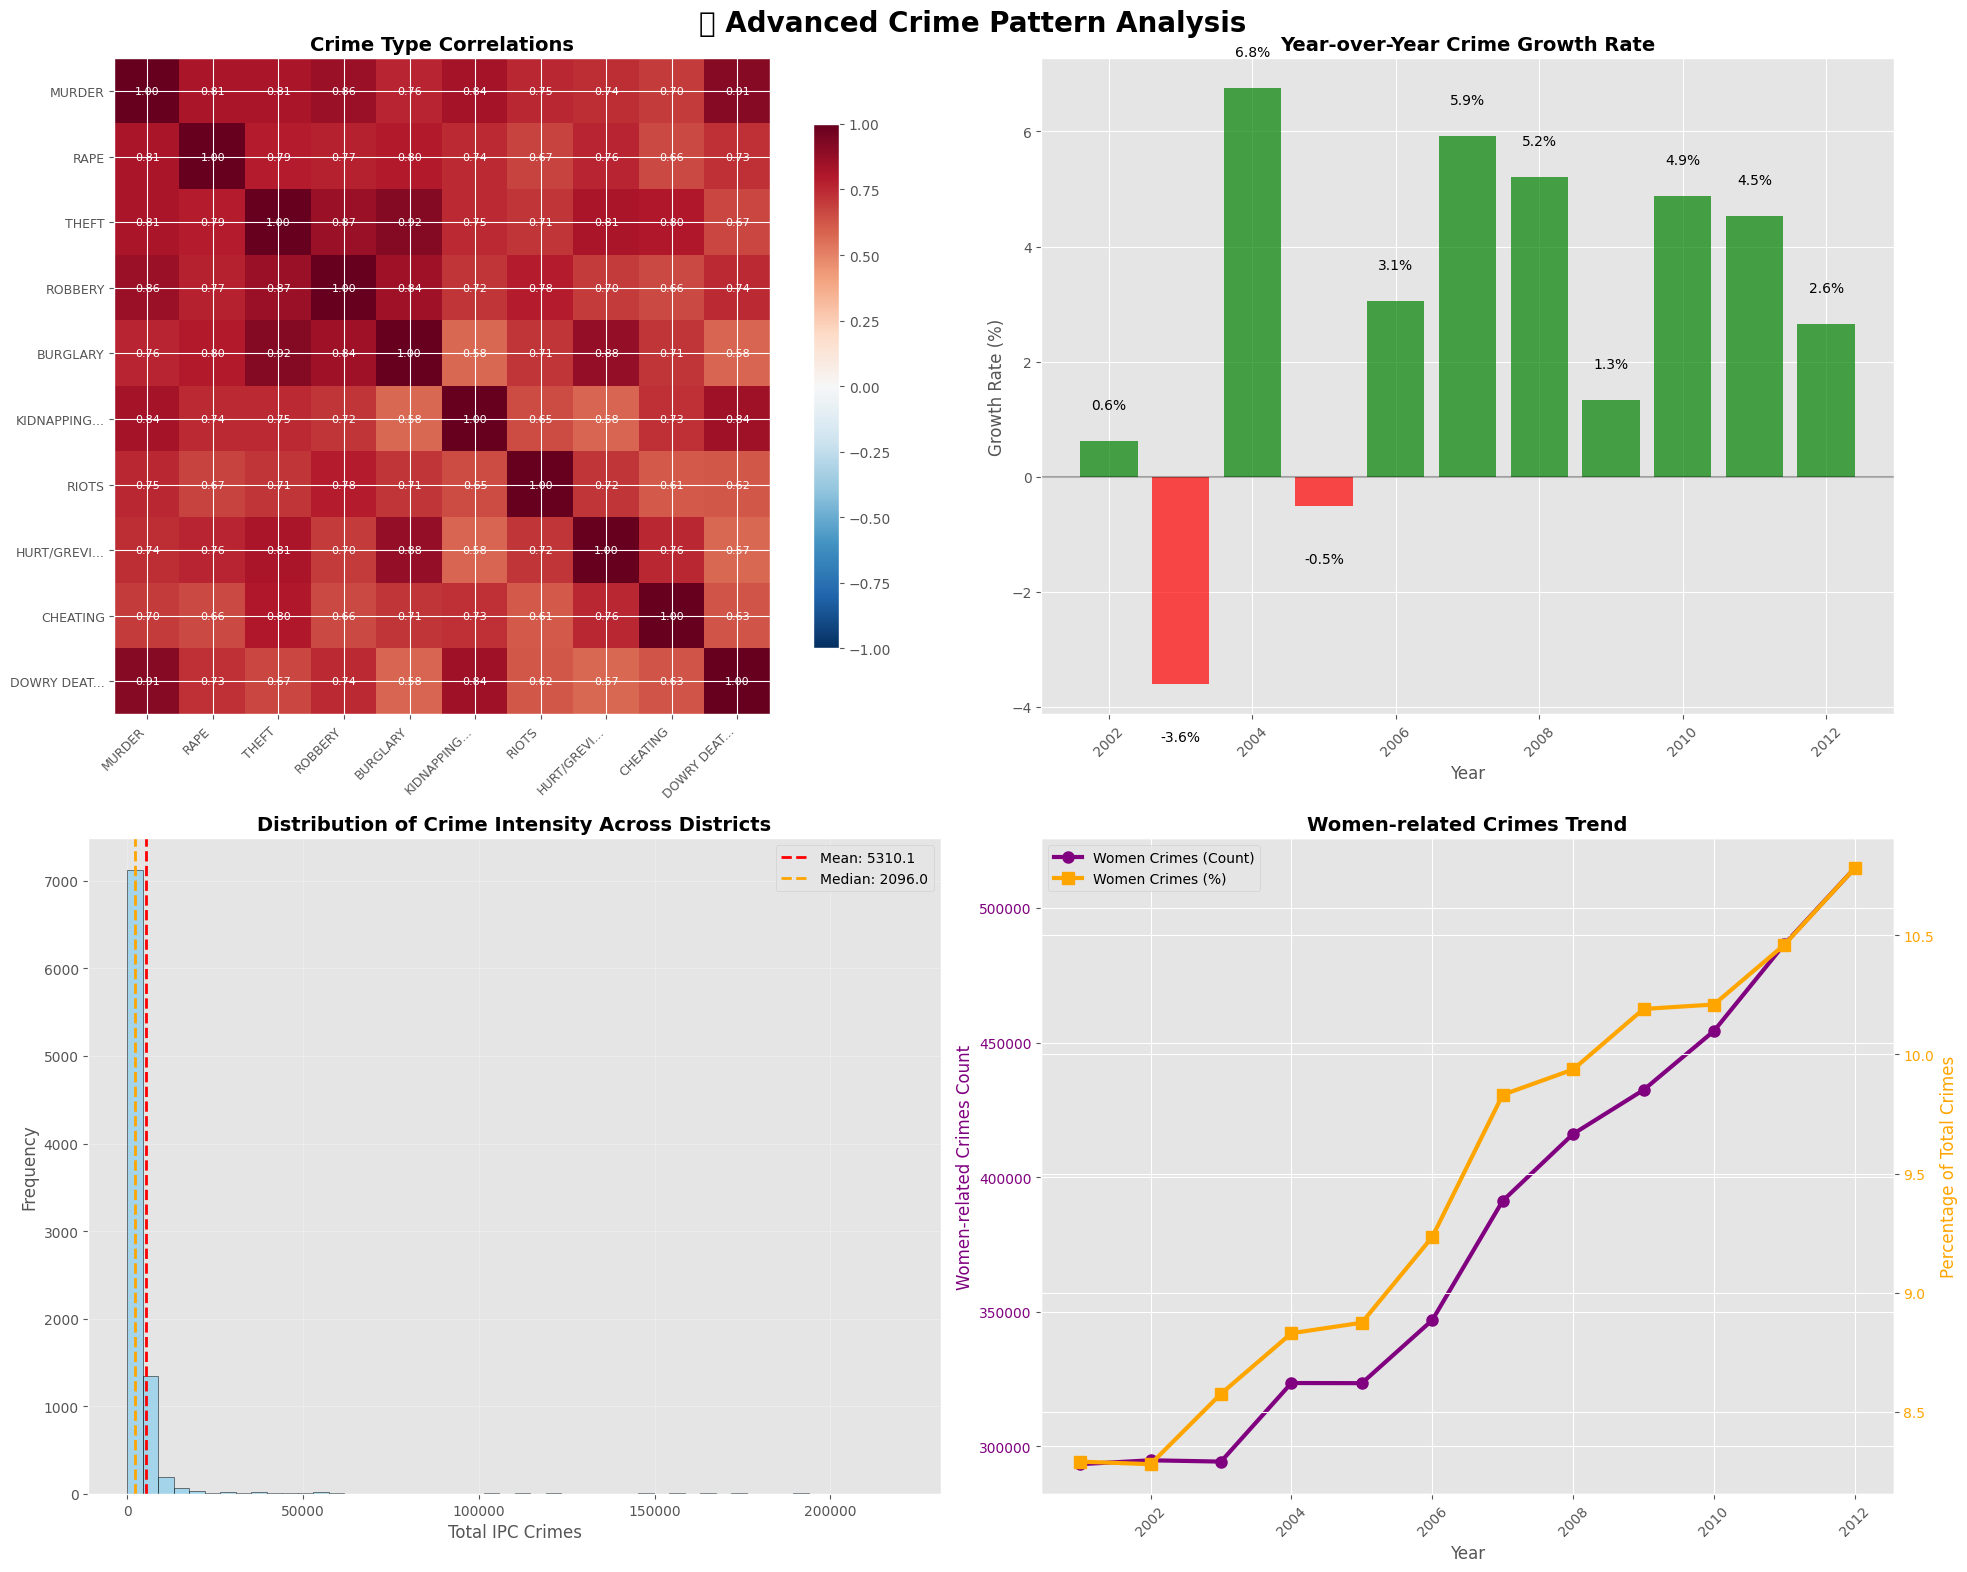

📈 Advanced Pattern Insights:
• Strongest positive correlation: 1.000
• Average annual growth rate: 2.80%
• Years with crime decrease: 2 out of 11
• Women-related crimes average: 9.46% of total crimes
• Crime distribution skewness: 7.95 (right-skewed)
• Most variable year: 2004 (6.8% change)


In [14]:
# 4. Advanced Pattern Analysis - Crime Correlations and Trends
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
fig.suptitle('🔬 Advanced Crime Pattern Analysis', fontsize=20, fontweight='bold')

# Crime correlation analysis
selected_crimes = ['MURDER', 'RAPE', 'THEFT', 'ROBBERY', 'BURGLARY', 'KIDNAPPING & ABDUCTION', 
                   'RIOTS', 'HURT/GREVIOUS HURT', 'CHEATING', 'DOWRY DEATHS']
correlation_matrix = df[selected_crimes].corr()

# Heatmap of crime correlations
im1 = axes[0,0].imshow(correlation_matrix, cmap='RdBu_r', vmin=-1, vmax=1)
axes[0,0].set_xticks(range(len(selected_crimes)))
axes[0,0].set_yticks(range(len(selected_crimes)))
axes[0,0].set_xticklabels([crime[:10] + '...' if len(crime) > 10 else crime for crime in selected_crimes], 
                         rotation=45, ha='right', fontsize=9)
axes[0,0].set_yticklabels([crime[:10] + '...' if len(crime) > 10 else crime for crime in selected_crimes], 
                         fontsize=9)
axes[0,0].set_title('Crime Type Correlations', fontsize=14, fontweight='bold')

# Add correlation values to heatmap
for i in range(len(selected_crimes)):
    for j in range(len(selected_crimes)):
        axes[0,0].text(j, i, f'{correlation_matrix.iloc[i, j]:.2f}', 
                      ha="center", va="center", color="white" if abs(correlation_matrix.iloc[i, j]) > 0.5 else "black",
                      fontsize=8)

plt.colorbar(im1, ax=axes[0,0], shrink=0.8)

# Year-over-year growth analysis
yearly_data = df.groupby('YEAR')['TOTAL IPC CRIMES'].sum()
growth_rates = yearly_data.pct_change() * 100

bars = axes[0,1].bar(growth_rates.index[1:], growth_rates.values[1:], 
                     color=['green' if x > 0 else 'red' for x in growth_rates.values[1:]], alpha=0.7)
axes[0,1].axhline(y=0, color='black', linestyle='-', alpha=0.3)
axes[0,1].set_title('Year-over-Year Crime Growth Rate', fontsize=14, fontweight='bold')
axes[0,1].set_xlabel('Year')
axes[0,1].set_ylabel('Growth Rate (%)')
axes[0,1].tick_params(axis='x', rotation=45)

# Add value labels
for bar in bars:
    height = bar.get_height()
    axes[0,1].text(bar.get_x() + bar.get_width()/2., height + (0.5 if height > 0 else -0.8),
                   f'{height:.1f}%', ha='center', va='bottom' if height > 0 else 'top', fontsize=10)

# Crime intensity distribution
crime_intensity = df['TOTAL IPC CRIMES']
axes[1,0].hist(crime_intensity, bins=50, color='skyblue', alpha=0.7, edgecolor='black')
axes[1,0].axvline(crime_intensity.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {crime_intensity.mean():.1f}')
axes[1,0].axvline(crime_intensity.median(), color='orange', linestyle='--', linewidth=2, label=f'Median: {crime_intensity.median():.1f}')
axes[1,0].set_title('Distribution of Crime Intensity Across Districts', fontsize=14, fontweight='bold')
axes[1,0].set_xlabel('Total IPC Crimes')
axes[1,0].set_ylabel('Frequency')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# Women-related crimes analysis
women_crimes = ['RAPE', 'CUSTODIAL RAPE', 'OTHER RAPE', 'KIDNAPPING AND ABDUCTION OF WOMEN AND GIRLS', 
                'DOWRY DEATHS', 'ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY', 
                'INSULT TO MODESTY OF WOMEN', 'CRUELTY BY HUSBAND OR HIS RELATIVES']

# Calculate yearly trends for women-related crimes
yearly_women_crimes = df.groupby('YEAR')[women_crimes].sum().sum(axis=1)
yearly_total_crimes = df.groupby('YEAR')['TOTAL IPC CRIMES'].sum()
women_crime_percentage = (yearly_women_crimes / yearly_total_crimes * 100)

line1 = axes[1,1].plot(yearly_women_crimes.index, yearly_women_crimes.values, 
                       marker='o', linewidth=3, color='purple', markersize=8, label='Women Crimes (Count)')
axes[1,1].set_xlabel('Year')
axes[1,1].set_ylabel('Women-related Crimes Count', color='purple')
axes[1,1].tick_params(axis='y', labelcolor='purple')
axes[1,1].tick_params(axis='x', rotation=45)

# Create second y-axis for percentage
ax2 = axes[1,1].twinx()
line2 = ax2.plot(women_crime_percentage.index, women_crime_percentage.values, 
                 marker='s', linewidth=3, color='orange', markersize=8, label='Women Crimes (%)')
ax2.set_ylabel('Percentage of Total Crimes', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

axes[1,1].set_title('Women-related Crimes Trend', fontsize=14, fontweight='bold')

# Combine legends
lines1, labels1 = axes[1,1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
axes[1,1].legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

# Statistical insights
print(f"📈 Advanced Pattern Insights:")
print(f"• Strongest positive correlation: {correlation_matrix.unstack().sort_values(ascending=False).iloc[1]:.3f}")
print(f"• Average annual growth rate: {growth_rates.mean():.2f}%")
print(f"• Years with crime decrease: {len(growth_rates[growth_rates < 0])} out of {len(growth_rates)-1}")
print(f"• Women-related crimes average: {women_crime_percentage.mean():.2f}% of total crimes")
print(f"• Crime distribution skewness: {crime_intensity.skew():.2f} (right-skewed)" if crime_intensity.skew() > 0 else f"• Crime distribution skewness: {crime_intensity.skew():.2f} (left-skewed)")
print(f"• Most variable year: {growth_rates.abs().idxmax()} ({growth_rates[growth_rates.abs().idxmax()]:.1f}% change)")

/tmp/ipykernel_8596/1594676867.py:115: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/cookie/aaa/ml/eda/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/cookie/aaa/ml/eda/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


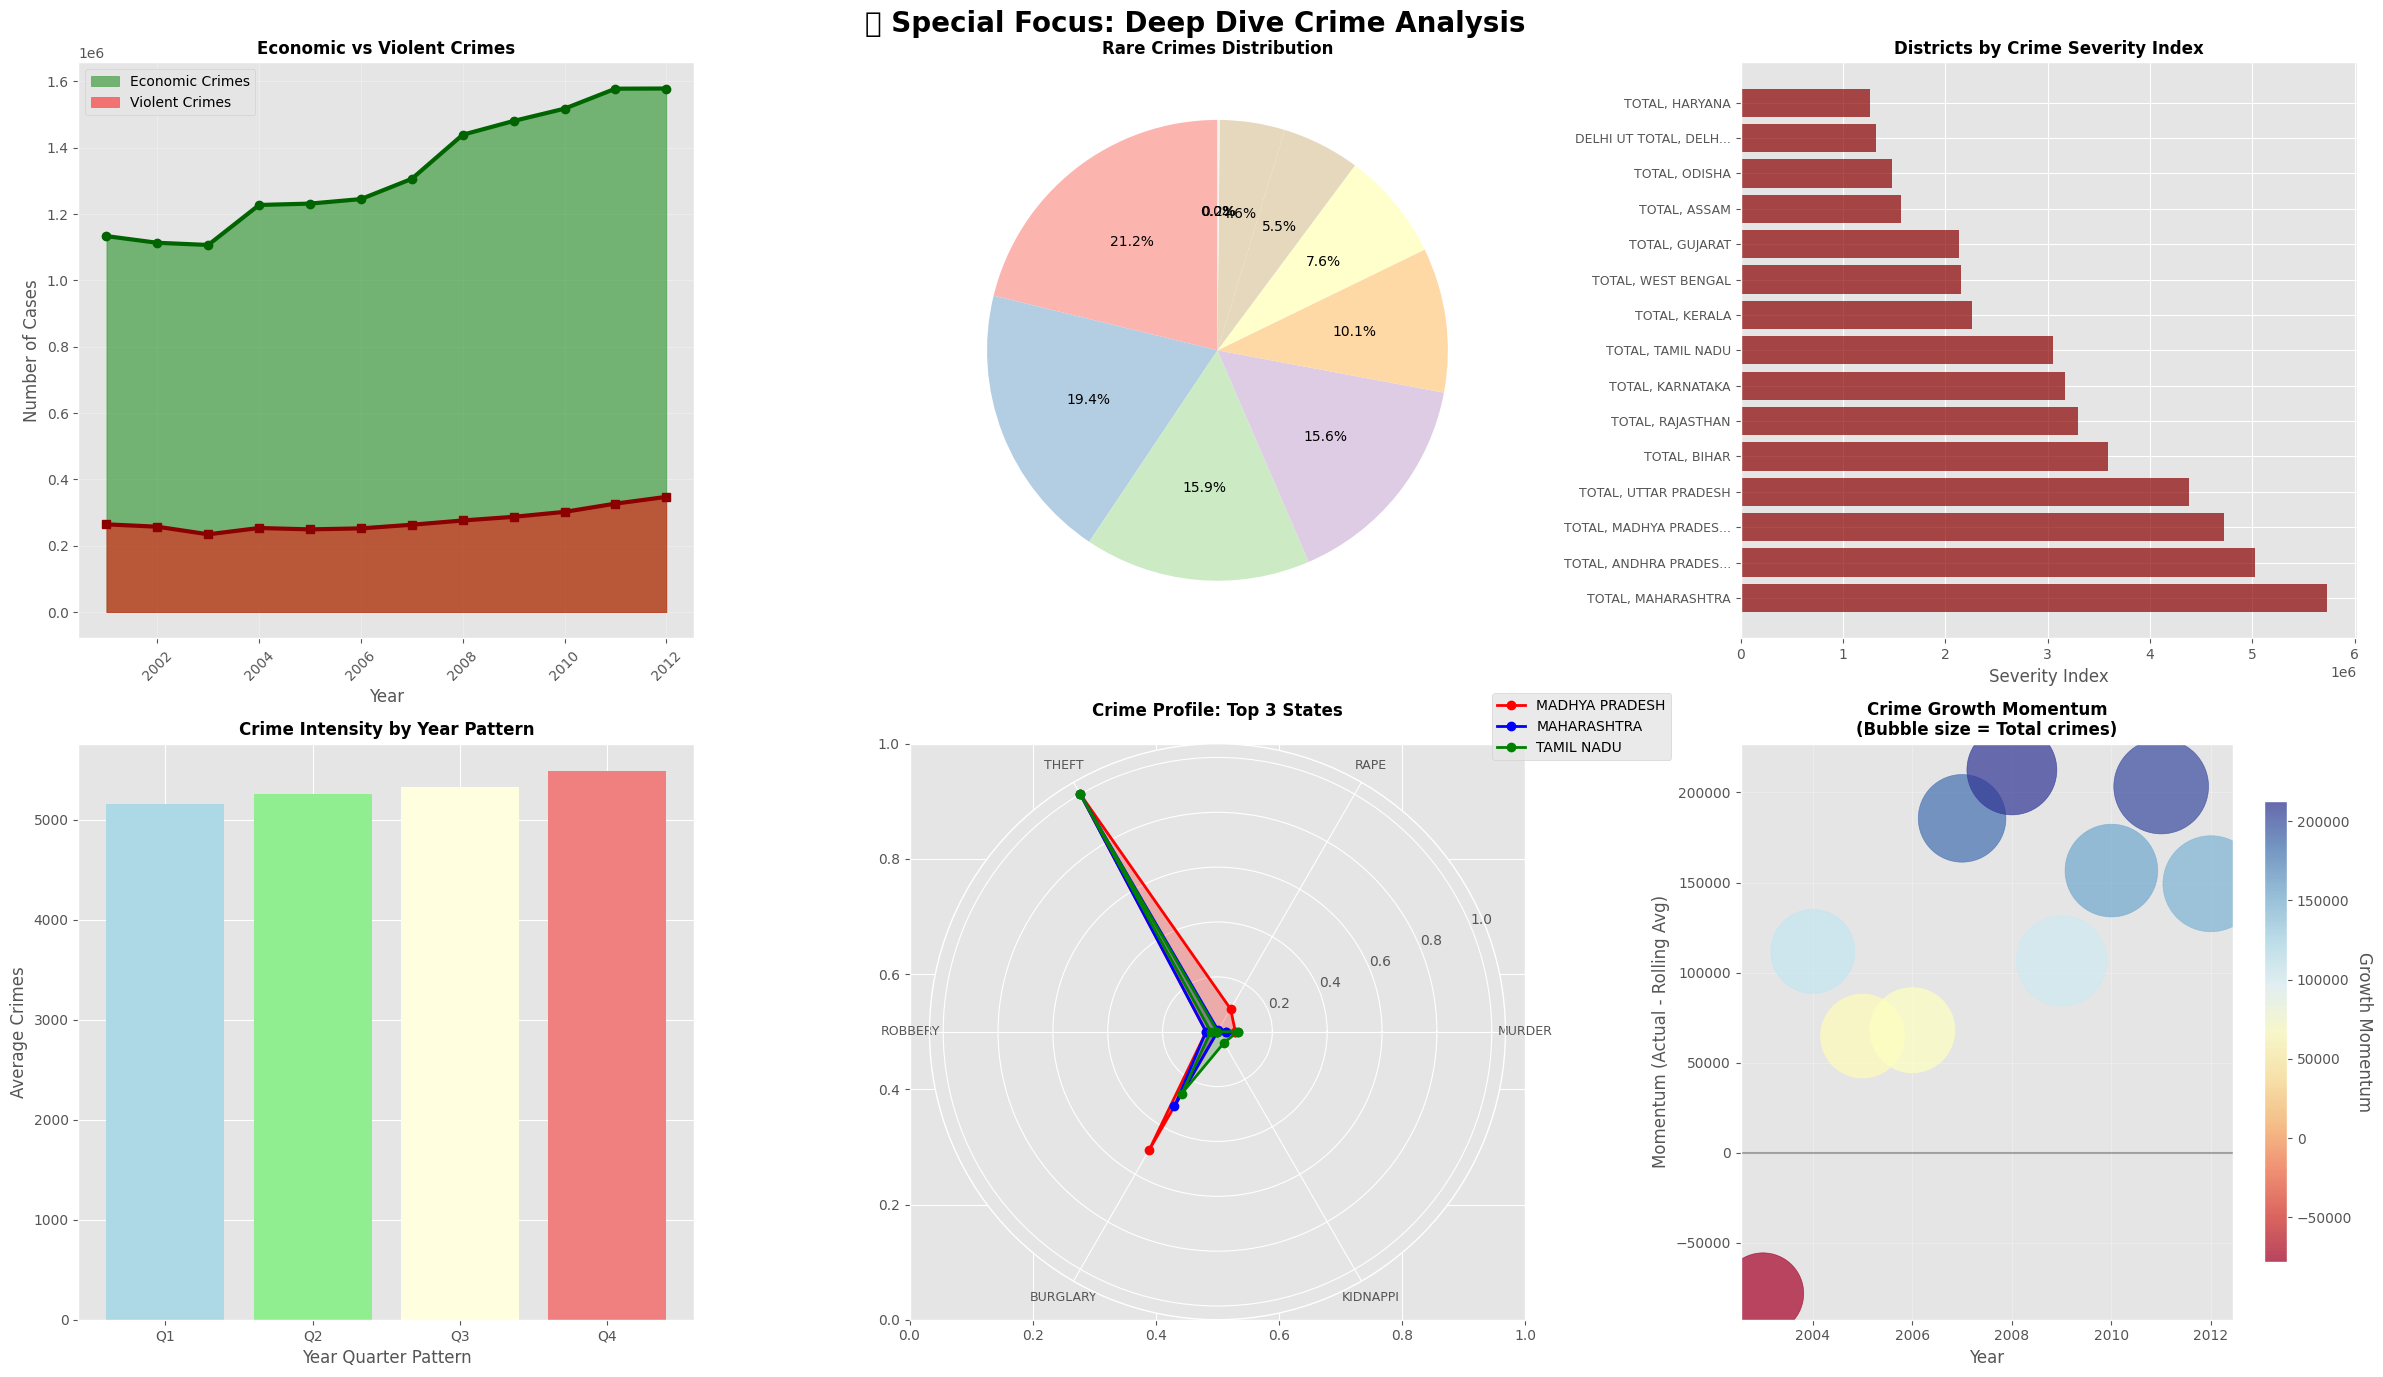

🎯 Special Insights:
• Economic crimes total: 15,958,792 vs Violent crimes: 3,316,380
• Economic-to-violent ratio: 4.8:1
• Highest severity district: TOTAL, MAHARASHTRA
• Most stable crime pattern quarter: Q1
• Strongest growth momentum year: 2008
• Crime diversity index (std of crime types): 3861132.0

📊 Complete Dataset Summary:
• Total records analyzed: 9,017
• Time span: 12 years
• Total crimes recorded: 47,881,308
• Daily average crimes: 10931.8
• Peak crime year: 2012 (4,774,376 crimes)
• Lowest crime year: 2003 (3,432,240 crimes)


In [ ]:
# 5. Special Focus Analysis - Unique Crime Insights
fig, axes = plt.subplots(2, 3, figsize=(24, 14))
fig.suptitle('🎯 Special Focus: Deep Dive Crime Analysis', fontsize=20, fontweight='bold')

# Economic vs Violent Crime Comparison
economic_crimes = ['THEFT', 'AUTO THEFT', 'OTHER THEFT', 'CHEATING', 'CRIMINAL BREACH OF TRUST', 'COUNTERFIETING']
violent_crimes = ['MURDER', 'ATTEMPT TO MURDER', 'RAPE', 'KIDNAPPING & ABDUCTION', 'DACOITY', 'ROBBERY']

yearly_economic = df.groupby('YEAR')[economic_crimes].sum().sum(axis=1)
yearly_violent = df.groupby('YEAR')[violent_crimes].sum().sum(axis=1)

axes[0,0].fill_between(yearly_economic.index, yearly_economic.values, alpha=0.5, color='green', label='Economic Crimes')
axes[0,0].fill_between(yearly_violent.index, yearly_violent.values, alpha=0.5, color='red', label='Violent Crimes')
axes[0,0].plot(yearly_economic.index, yearly_economic.values, linewidth=3, color='darkgreen', marker='o')
axes[0,0].plot(yearly_violent.index, yearly_violent.values, linewidth=3, color='darkred', marker='s')
axes[0,0].set_title('Economic vs Violent Crimes', fontsize=12, fontweight='bold')
axes[0,0].set_xlabel('Year')
axes[0,0].set_ylabel('Number of Cases')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)
axes[0,0].tick_params(axis='x', rotation=45)

# Rare vs Common Crimes
crime_totals = df[crime_columns].sum().sort_values(ascending=False)
rare_crimes = crime_totals.tail(10)  # Bottom 10
common_crimes = crime_totals.head(10)  # Top 10

# Pie chart for rare crimes
colors_rare = plt.cm.Pastel1(np.linspace(0, 1, len(rare_crimes)))
wedges1, texts1, autotexts1 = axes[0,1].pie(rare_crimes.values, autopct='%1.1f%%', 
                                           colors=colors_rare, startangle=90)
axes[0,1].set_title('Rare Crimes Distribution', fontsize=12, fontweight='bold')

# Crime severity index (custom metric)
severity_weights = {
    'MURDER': 10, 'RAPE': 9, 'CUSTODIAL RAPE': 9, 'KIDNAPPING & ABDUCTION': 8,
    'DACOITY': 7, 'ROBBERY': 6, 'ATTEMPT TO MURDER': 8, 'BURGLARY': 4,
    'THEFT': 3, 'RIOTS': 5, 'HURT/GREVIOUS HURT': 5, 'DOWRY DEATHS': 9
}

# Calculate severity index for each district
df['SEVERITY_INDEX'] = 0
for crime, weight in severity_weights.items():
    if crime in df.columns:
        df['SEVERITY_INDEX'] += df[crime] * weight

# Top districts by severity
severity_by_district = df.groupby(['STATE/UT', 'DISTRICT'])['SEVERITY_INDEX'].sum().reset_index()
severity_by_district['District_Label'] = severity_by_district['DISTRICT'] + ', ' + severity_by_district['STATE/UT']
top_severity = severity_by_district.sort_values('SEVERITY_INDEX', ascending=False).head(15)

bars = axes[0,2].barh(range(len(top_severity)), top_severity['SEVERITY_INDEX'], 
                      color='darkred', alpha=0.7)
axes[0,2].set_yticks(range(len(top_severity)))
axes[0,2].set_yticklabels([label[:20] + '...' if len(label) > 20 else label 
                          for label in top_severity['District_Label']], fontsize=9)
axes[0,2].set_title('Districts by Crime Severity Index', fontsize=12, fontweight='bold')
axes[0,2].set_xlabel('Severity Index')

# Crime intensity by year quarters (assuming data collection patterns)
df['YEAR_QUARTER'] = df['YEAR'].apply(lambda x: f"Q{((x-2001)%4)+1}")
quarterly_crimes = df.groupby('YEAR_QUARTER')['TOTAL IPC CRIMES'].mean()

axes[1,0].bar(quarterly_crimes.index, quarterly_crimes.values, 
              color=['lightblue', 'lightgreen', 'lightyellow', 'lightcoral'])
axes[1,0].set_title('Crime Intensity by Year Pattern', fontsize=12, fontweight='bold')
axes[1,0].set_xlabel('Year Quarter Pattern')
axes[1,0].set_ylabel('Average Crimes')

# Crime evolution radar chart for top 3 states
top_3_states = df.groupby('STATE/UT')['TOTAL IPC CRIMES'].sum().sort_values(ascending=False).head(3)

# Select key crime types for radar
radar_crimes = ['MURDER', 'RAPE', 'THEFT', 'ROBBERY', 'BURGLARY', 'KIDNAPPING & ABDUCTION']
angles = np.linspace(0, 2 * np.pi, len(radar_crimes), endpoint=False)
angles = np.concatenate((angles, [angles[0]]))  # Complete the circle

axes[1,1] = plt.subplot(2, 3, 5, projection='polar')
colors_radar = ['red', 'blue', 'green']

for i, state in enumerate(top_3_states.index):
    state_data = df[df['STATE/UT'] == state][radar_crimes].sum()
    # Normalize to 0-1 scale
    state_data_norm = (state_data - state_data.min()) / (state_data.max() - state_data.min())
    values = np.concatenate((state_data_norm.values, [state_data_norm.values[0]]))
    
    axes[1,1].plot(angles, values, 'o-', linewidth=2, label=state[:15], color=colors_radar[i])
    axes[1,1].fill(angles, values, alpha=0.25, color=colors_radar[i])

axes[1,1].set_xticks(angles[:-1])
axes[1,1].set_xticklabels([crime[:8] for crime in radar_crimes], fontsize=9)
axes[1,1].set_title('Crime Profile: Top 3 States', fontsize=12, fontweight='bold', pad=20)
axes[1,1].legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

# Calculate 3-year rolling average for growth stability
yearly_total = df.groupby('YEAR')['TOTAL IPC CRIMES'].sum()
rolling_avg = yearly_total.rolling(window=3).mean()
momentum = yearly_total - rolling_avg

axes[1,2].scatter(yearly_total.index, momentum.values, s=yearly_total.values/1000, 
                  c=momentum.values, cmap='RdYlBu', alpha=0.7)
axes[1,2].axhline(y=0, color='black', linestyle='-', alpha=0.3)
axes[1,2].set_title('Crime Growth Momentum\n(Bubble size = Total crimes)', fontsize=12, fontweight='bold')
axes[1,2].set_xlabel('Year')
axes[1,2].set_ylabel('Momentum (Actual - Rolling Avg)')
axes[1,2].grid(True, alpha=0.3)

# Add colorbar for momentum
cbar = plt.colorbar(axes[1,2].collections[0], ax=axes[1,2], shrink=0.8)
cbar.set_label('Growth Momentum', rotation=270, labelpad=15)

plt.tight_layout()
plt.show()

print(f"🎯 Special Insights:")
print(f"• Economic crimes total: {yearly_economic.sum():,} vs Violent crimes: {yearly_violent.sum():,}")
print(f"• Economic-to-violent ratio: {yearly_economic.sum()/yearly_violent.sum():.1f}:1")
print(f"• Highest severity district: {top_severity.iloc[0]['District_Label']}")
print(f"• Most stable crime pattern quarter: Q{quarterly_crimes.idxmin()[-1]}")
print(f"• Strongest growth momentum year: {momentum.idxmax()}")
print(f"• Crime diversity index (std of crime types): {crime_totals.std():.1f}")

# Final summary statistics
print(f"\n📊 Complete Dataset Summary:")
print(f"• Total records analyzed: {len(df):,}")
print(f"• Time span: {df['YEAR'].max() - df['YEAR'].min() + 1} years")
print(f"• Total crimes recorded: {df['TOTAL IPC CRIMES'].sum():,}")
print(f"• Daily average crimes: {df['TOTAL IPC CRIMES'].sum() / (12 * 365):.1f}")
print(f"• Peak crime year: {yearly_total.idxmax()} ({yearly_total.max():,} crimes)")
print(f"• Lowest crime year: {yearly_total.idxmin()} ({yearly_total.min():,} crimes)")